# GLM - Task 3

Uses the preprocessed fMRI data from task 1. The paths are in `paths.py`.


In [1]:
import os
import os.path as op
import sys
sys.path.append('.')
from paths import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from nilearn import image, datasets
from nilearn.glm.first_level import FirstLevelModel, make_first_level_design_matrix
from nilearn.glm import threshold_stats_img
from nilearn.plotting import plot_design_matrix, plot_contrast_matrix, plot_stat_map

# use the same slices for the maps
AXIAL_CUTS = (-20, -10, 0, 10, 20, 30, 40, 50)

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

In [2]:
# View the data and events
fmri_img = nib.load(FUNC_PATH)
events = pd.read_csv(EVENTS_PATH)

n_scans = fmri_img.shape[3]
tr = float(fmri_img.header.get_zooms()[3])
frame_times = np.arange(n_scans) * tr
print("Scans:", n_scans, "TR:", tr, "Run length:", n_scans * tr)

print("Event types:")
print(events["trial_type"].value_counts())

Scans: 316 TR: 0.7200000286102295 Run length: 227.52000904083252
Event types:
trial_type
present_math      9
math              9
question_math     9
response_math     9
cue               7
story             4
present_story     4
question_story    4
response_story    4
Name: count, dtype: int64


## 3a Design matrix

Story and math blocks, plus motion parameters and drifts.


,onset,duration,trial_type
0,0.241,28.270,story
6,30.095,12.241,math
10,42.570,12.312,math
15,56.524,27.147,story
19,85.206,12.667,math


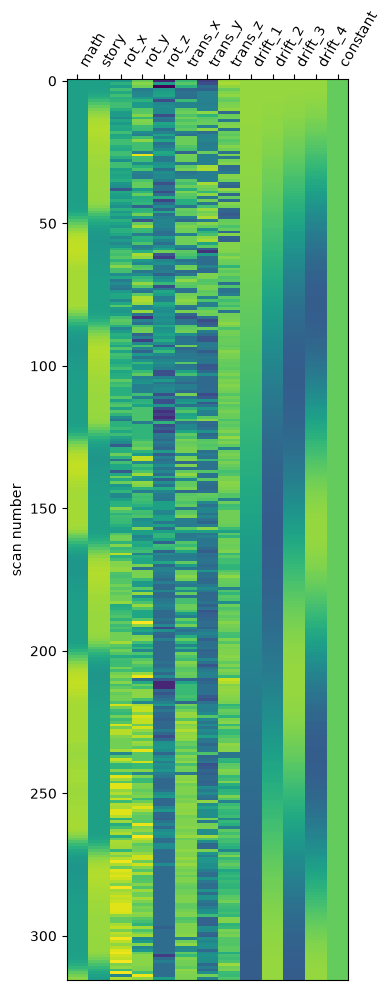

Columns in design matrix: ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']


In [3]:
events_glm = events[
    events["trial_type"].isin(["story", "math"])
].copy()
display(events_glm.head())

motion_params = pd.read_csv(
    MOTION_PAR,
    sep=r"\s+",
    header=None,
    names=["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]
)
assert len(motion_params) == n_scans

design_matrix = make_first_level_design_matrix(
    frame_times=frame_times,
    events=events_glm,
    hrf_model="spm",
    drift_model="cosine",
    high_pass=0.01,
    add_regs=motion_params.to_numpy(),
    add_reg_names=motion_params.columns.tolist()
)

plot_design_matrix(design_matrix)
plt.savefig(op.join(FIG_DIR, "3a_design_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()
print("Columns in design matrix:", design_matrix.columns.tolist())

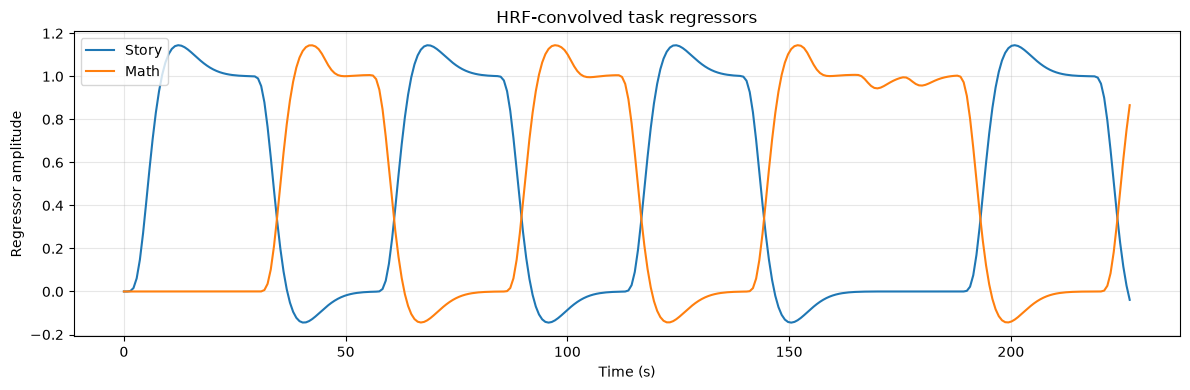

In [4]:
# Plot the convolved task regressors
plt.figure(figsize=(12, 4))
plt.plot(frame_times, design_matrix["story"], label="Story")
plt.plot(frame_times, design_matrix["math"], label="Math")
plt.xlabel("Time (s)"); plt.ylabel("Regressor amplitude")
plt.title("HRF-convolved task regressors"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(op.join(FIG_DIR, "3a_task_regressors.png"), dpi=200)
plt.show()

## 3b Correlation Matrix

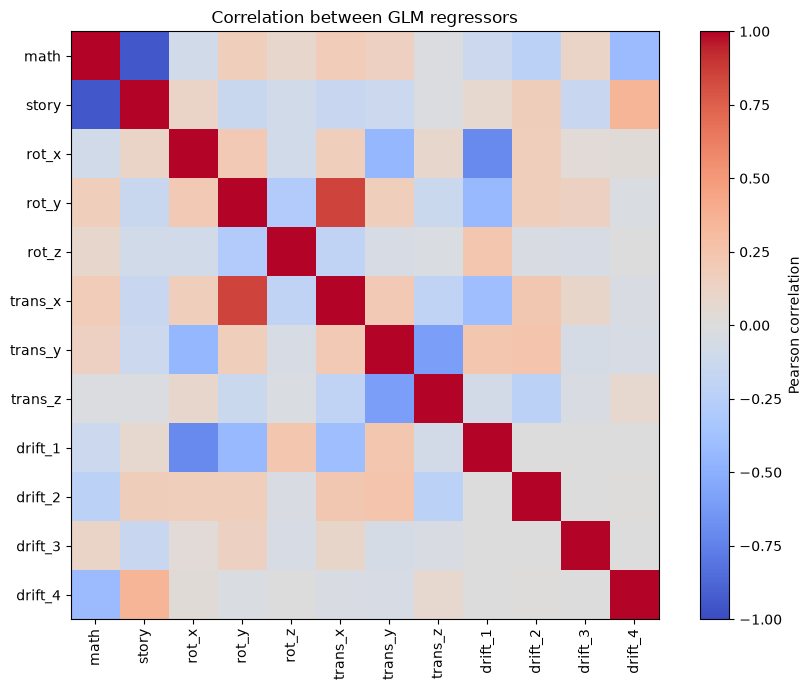

story vs math: -0.941


,math,story,rot_x,rot_y,rot_z,trans_x,trans_y,trans_z,drift_1,drift_2,drift_3,drift_4
story,-0.941,1.000,0.113,-0.138,-0.091,-0.142,-0.118,-0.022,0.077,0.172,-0.143,0.346
math,1.000,-0.941,-0.088,0.172,0.090,0.184,0.142,-0.017,-0.125,-0.225,0.112,-0.415


In [5]:
corr_matrix = design_matrix.drop(columns=["constant"]).corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix))); ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticks(range(len(corr_matrix))); ax.set_yticklabels(corr_matrix.index)
plt.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between GLM regressors")
plt.tight_layout()
plt.savefig(op.join(FIG_DIR, "3b_correlation_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

print("story vs math:", round(corr_matrix.loc["story", "math"], 3))
display(corr_matrix.loc[["story", "math"]].round(3))

## 3c GLM Fit and Statistical Maps for Story and Math

Story and Math regressor z-maps are shown without and without FDR correction.



In [6]:
preprocessed_path = SMOOTH_PATH + ".nii.gz"
preprocessed_fmri_img = nib.load(preprocessed_path)
assert preprocessed_fmri_img.shape[3] == len(design_matrix)

fmri_glm = FirstLevelModel(
    t_r=float(tr),
    noise_model="ar1",
    standardize=False,
    hrf_model="spm",
    drift_model="cosine",
    high_pass=0.01
)
fmri_glm = fmri_glm.fit(
    preprocessed_fmri_img,
    design_matrices=design_matrix
)
mask_img = fmri_glm.masker_.mask_img_
print("GLM fitted")

GLM fitted


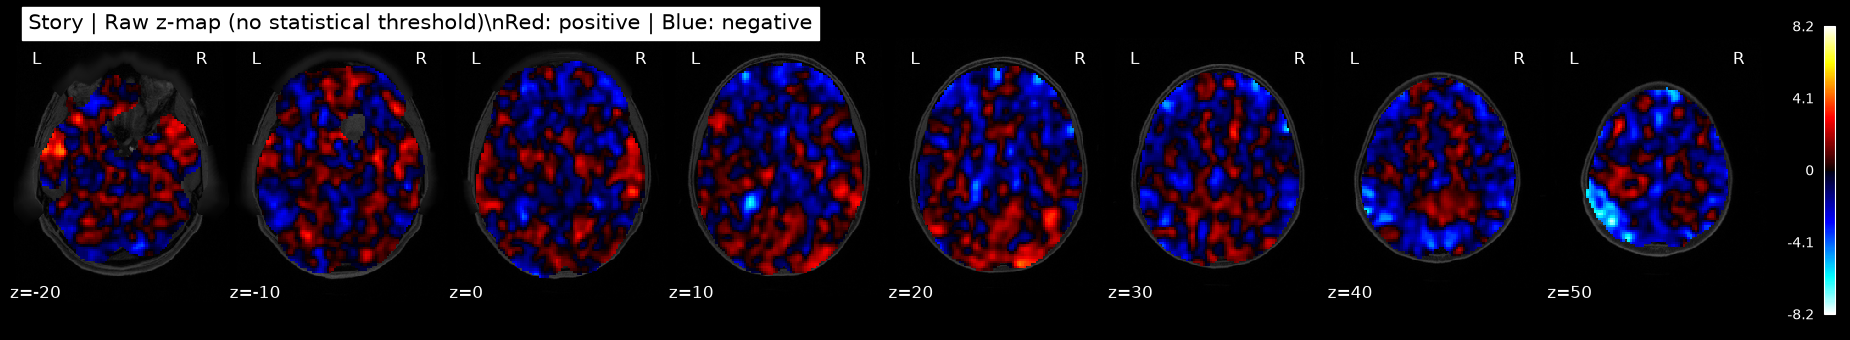

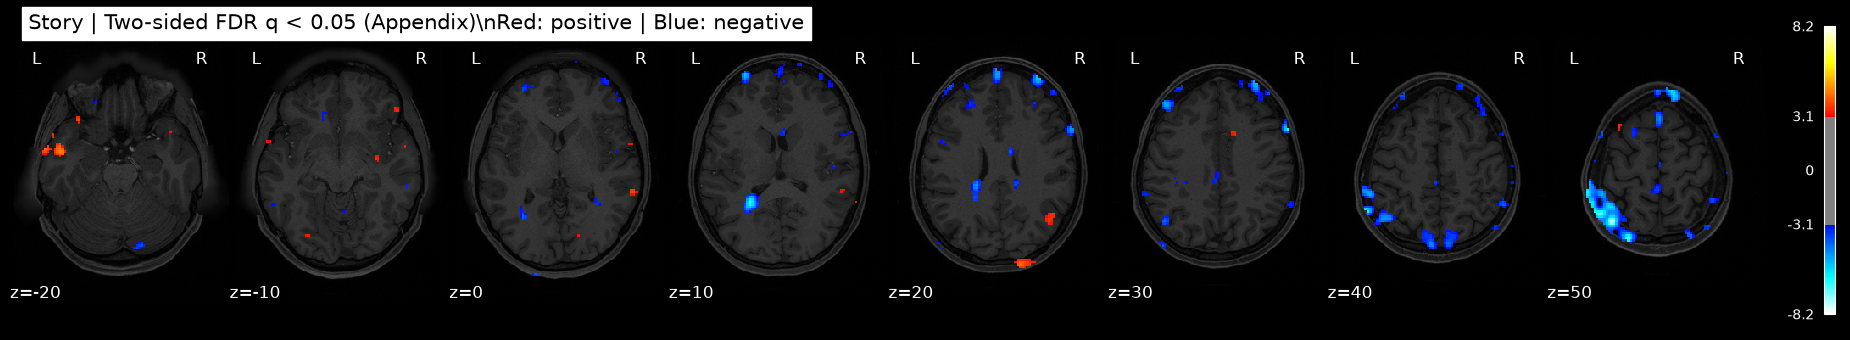

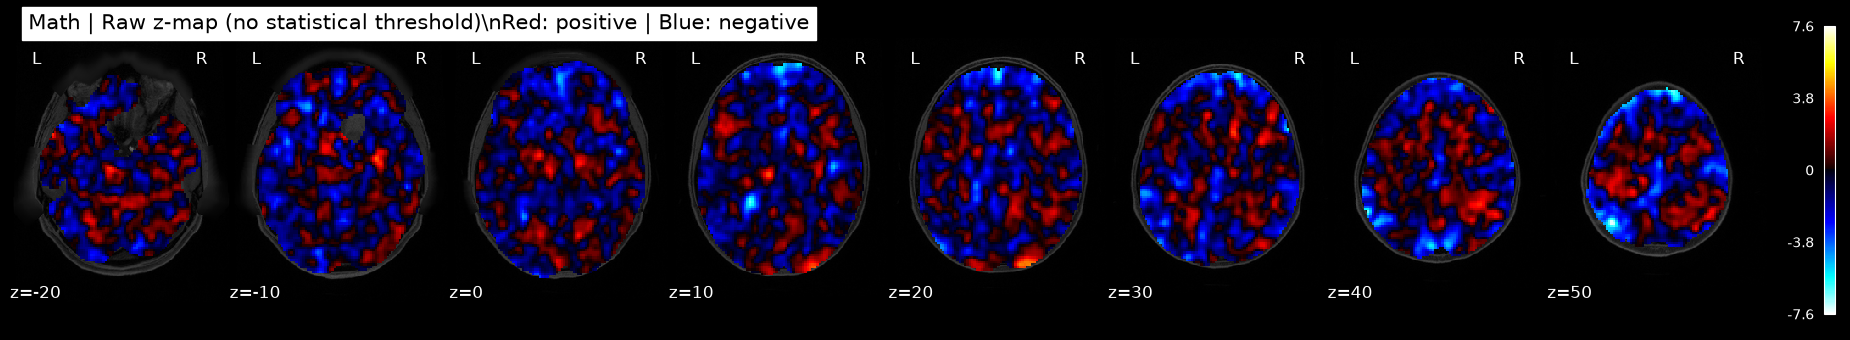

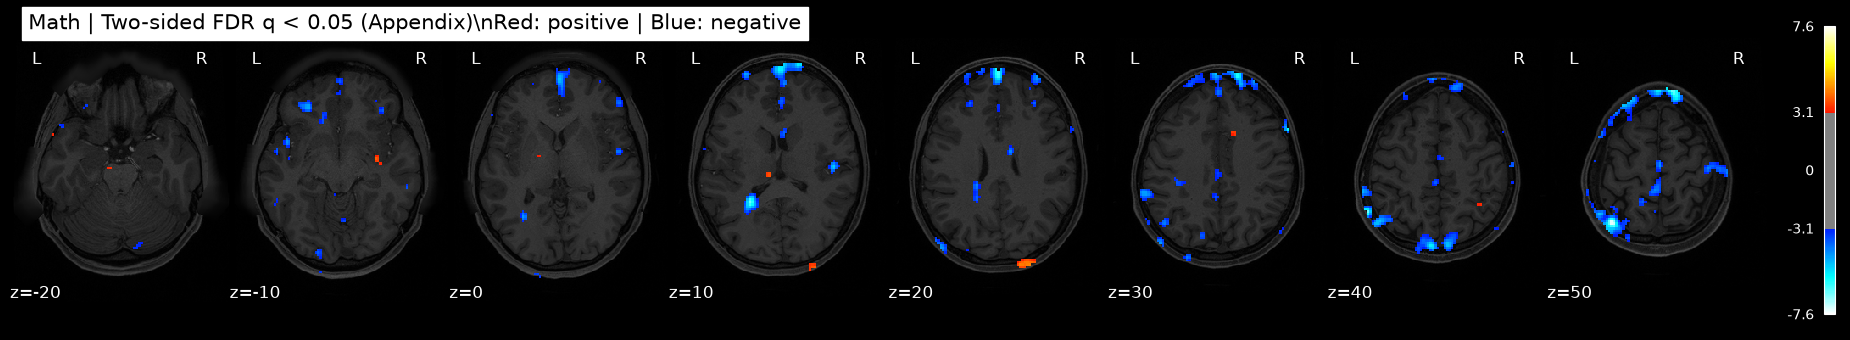

In [12]:
# Task z-maps: raw maps and with FDR 
story_zmap = fmri_glm.compute_contrast("story", output_type="z_score")
math_zmap = fmri_glm.compute_contrast("math", output_type="z_score")

maps = {"Story": story_zmap, "Math": math_zmap}
corrected_maps = {}
thresholds = {}

for title, zmap in maps.items():
    corrected_map, threshold = threshold_stats_img(
        zmap, mask_img=mask_img, alpha=0.05,
        height_control="fdr", two_sided=True
    )
    corrected_maps[title] = corrected_map
    thresholds[title] = threshold
    vmax = max(1.0, float(np.nanmax(np.abs(zmap.get_fdata()))))

    for subtitle, stat_img, cutoff, suffix in [
        ("Raw z-map (no statistical threshold)", zmap, 0.0, "raw"),
        ("Two-sided FDR q < 0.05 (Appendix)", corrected_map, threshold, "fdr"),
    ]:
        if not np.isfinite(cutoff):
            print(f"{title}: no voxels pass FDR")
            continue
        view = plot_stat_map(
            stat_img, bg_img=ANAT_PATH, threshold=cutoff,
            display_mode="z", cut_coords=AXIAL_CUTS,
            cmap="cold_hot", symmetric_cbar=True, vmax=vmax,
            title=f"{title} | {subtitle}\\nRed: positive | Blue: negative",
            colorbar=True
        )
        view.savefig(op.join(FIG_DIR, f"3c_{title.lower()}_{suffix}.png"), dpi=200)
        plt.show()


## 3d Story vs Math

The Story vs. Math contrast is tested with two-sided FDR correction (q < 0.05). Red indicates Story > Math and blue indicates Math > Story.


,math,story,rot_x,rot_y,rot_z,trans_x,trans_y,trans_z,drift_1,drift_2,drift_3,drift_4,constant
Story - Math,-1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Story vs Math FDR threshold: 2.41


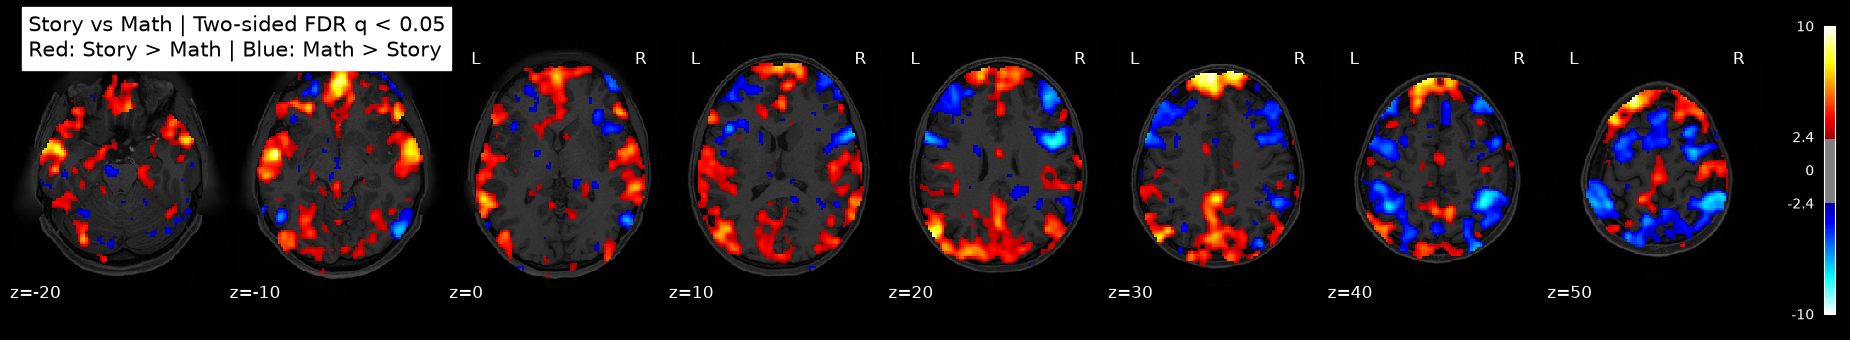

In [14]:
# Story - Math contrast
columns = design_matrix.columns
story_vs_math = np.zeros(len(columns))
story_vs_math[columns.get_loc("story")] = 1
story_vs_math[columns.get_loc("math")] = -1
display(pd.DataFrame([story_vs_math], index=["Story - Math"], columns=columns))


# Story - Math contrast
story_vs_math_zmap = fmri_glm.compute_contrast(story_vs_math, output_type="z_score")

# Two-sided FDR correction for all directional contrasts
sm_thr_map, sm_thr = threshold_stats_img(
    story_vs_math_zmap, mask_img=mask_img, alpha=0.05,
    height_control="fdr", two_sided=True
)
print(f"Story vs Math FDR threshold: {sm_thr:.2f}")
vmax = max(1.0, float(np.nanmax(np.abs(story_vs_math_zmap.get_fdata()))))

if np.isfinite(sm_thr):
    view = plot_stat_map(
        sm_thr_map, bg_img=ANAT_PATH, threshold=sm_thr,
        display_mode="z", cut_coords=AXIAL_CUTS,
        cmap="cold_hot", symmetric_cbar=True, vmax=vmax,
        title="Story vs Math | Two-sided FDR q < 0.05\nRed: Story > Math | Blue: Math > Story",
        colorbar=True
    )
    view.savefig(op.join(FIG_DIR, "3d_story_vs_math_fdr.png"), dpi=200)
    plt.show()
else:
    print("No Story vs Math voxels survive FDR correction")


In [9]:
# Save statistical maps
nib.save(story_zmap, op.join(RESULTS_DIR, "story_zmap.nii.gz"))
nib.save(math_zmap, op.join(RESULTS_DIR, "math_zmap.nii.gz"))
nib.save(story_vs_math_zmap, op.join(RESULTS_DIR, "story_vs_math_zmap.nii.gz"))
nib.save(sm_thr_map, op.join(RESULTS_DIR, "story_vs_math_zmap_fdr.nii.gz"))


## 3e Functional networks

The two directional Story vs. Math maps show only voxels surviving two-sided FDR correction (q < 0.05), overlaid with all seven Yeo networks. Red indicates Story > Math and blue indicates Math > Story. 


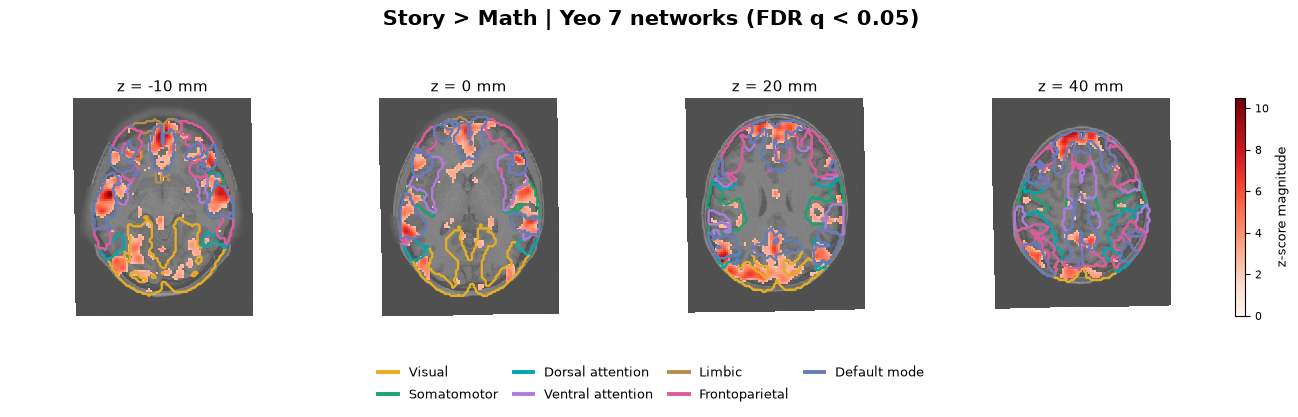

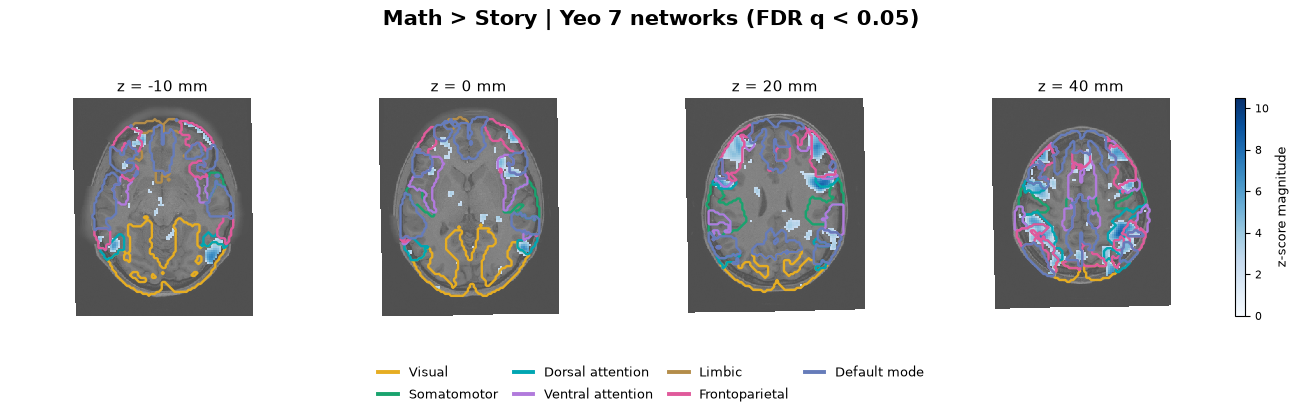

In [10]:
# Directional Story−Math overlays: all seven Yeo networks
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib import colors as mcolors
from nilearn.plotting.cm import cold_hot

FOUR_CUTS = (-10, 0, 20, 40)
NETWORKS = {
    "Vis": "Visual", "SomMot": "Somatomotor",
    "DorsAttn": "Dorsal attention", "SalVentAttn": "Ventral attention",
    "Limbic": "Limbic", "Cont": "Frontoparietal", "Default": "Default mode"
}
NETWORK_COLORS = {
    "Visual": "#E6AD22", "Somatomotor": "#19A36E",
    "Dorsal attention": "#00A6B2", "Ventral attention": "#B17ADC",
    "Limbic": "#B48D4A", "Frontoparietal": "#E05A9B",
    "Default mode": "#667CBA"
}

def make_mask_like(reference, array):
    return image.new_img_like(reference, array.astype(np.uint8), copy_header=True)

def plot_atlas_slices(stat_img, atlas_img, regions, title, filename,
                      cmap, vmax, threshold, legend_cols=4):
    if not np.isfinite(threshold):
        print(f"{title}: no FDR-significant voxels")
        return
    fig = plt.figure(figsize=(13.5, 4.35), facecolor="white")
    gs = fig.add_gridspec(1, 5, left=0.025, right=0.94, top=0.76,
                          bottom=0.26, wspace=0.005,
                          width_ratios=[1, 1, 1, 1, 0.035])
    axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
    cax = fig.add_subplot(gs[0, 4])
    fig.suptitle(title, x=0.5, y=0.965, fontsize=15, fontweight="bold")
    for ax, cut in zip(axes, FOUR_CUTS):
        view = plot_stat_map(
            stat_img, bg_img=ANAT_PATH, axes=ax, figure=fig,
            display_mode="z", cut_coords=[cut], threshold=threshold,
            cmap=cmap, vmax=vmax, symmetric_cbar=False, colorbar=False,
            annotate=False, draw_cross=False, black_bg=False
        )
        for name, mask, color in regions:
            view.add_contours(mask, levels=[0.5], colors=[color], linewidths=1.7)
        ax.set_title(f"z = {cut} mm", fontsize=11, pad=5, loc="center")
    cb = fig.colorbar(ScalarMappable(norm=Normalize(0, vmax), cmap=cmap), cax=cax)
    cb.set_label("z-score magnitude", fontsize=9)
    cb.ax.tick_params(labelsize=8)
    legend = [Line2D([0], [0], color=color, lw=2.8, label=name)
              for name, _, color in regions]
    fig.legend(handles=legend, loc="lower center", bbox_to_anchor=(0.5, 0.035),
               ncol=legend_cols, frameon=False, fontsize=9.5,
               handlelength=1.5, columnspacing=1.2, labelspacing=0.6)
    fig.savefig(op.join(FIG_DIR, filename), dpi=220, bbox_inches="tight", pad_inches=0.12)
    plt.show()

schaefer = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2)
labels = [x.decode() if isinstance(x, bytes) else str(x) for x in schaefer.labels]
if len(labels) == 400:
    labels = ["Background"] + labels
atlas_img = image.resample_to_img(schaefer.maps, sm_thr_map, interpolation="nearest")
parcels = np.rint(atlas_img.get_fdata()).astype(int)
network_regions = []
for short, name in NETWORKS.items():
    ids = [i for i in range(1, len(labels)) if labels[i].split("_")[2] == short]
    region_mask = make_mask_like(atlas_img, np.isin(parcels, ids))
    network_regions.append((name, region_mask, NETWORK_COLORS[name]))

z = sm_thr_map.get_fdata()
max_z = max(float(sm_thr) + 0.01, float(np.nanmax(np.abs(story_vs_math_zmap.get_fdata()))))
for label, sign, color_map, fname in [
    ("Story > Math", 1, "Reds", "3e_story_gt_math_all_networks.png"),
    ("Math > Story", -1, "Blues", "3e_math_gt_story_all_networks.png")
]:
    signed = np.where(z * sign > 0, z * sign, 0.0)
    signed_img = image.new_img_like(sm_thr_map, signed, copy_header=True)
    plot_atlas_slices(
        signed_img, atlas_img, network_regions,
        f"{label} | Yeo 7 networks (FDR q < 0.05)",
        fname, color_map, max_z, sm_thr, legend_cols=4
    )


## 3f Semantic and language-related regions

Only the FDR-corrected Story > Math contrast (two-sided q < 0.05) is shown at axial cuts -22, -6, +20, +38 mm.


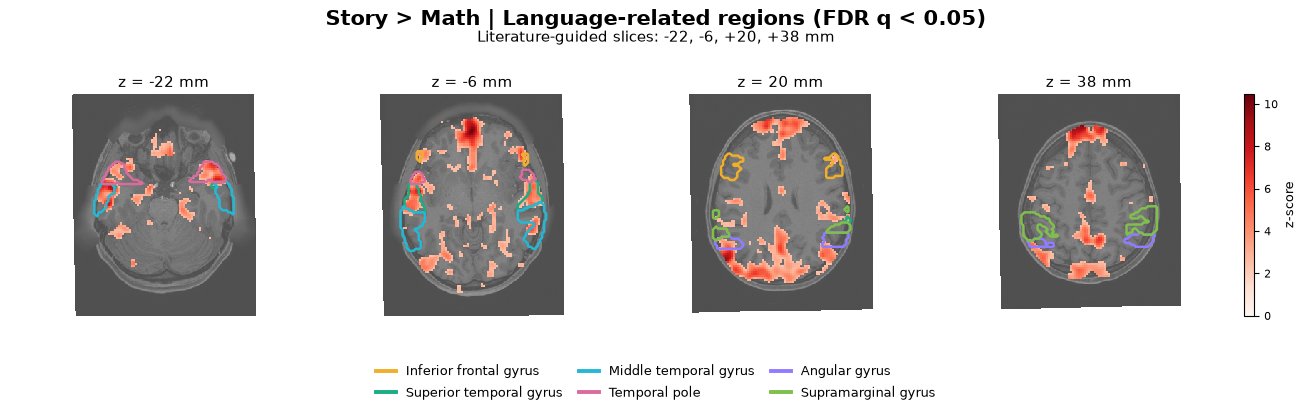

In [15]:
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

SEMANTIC_CUTS = (-22, -6, 20, 38)

ho = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
ho_labels = [x.decode() if isinstance(x, bytes) else str(x) for x in ho.labels]
ho_img = image.resample_to_img(ho.maps, story_vs_math_zmap, interpolation="nearest")
ho_data = np.rint(ho_img.get_fdata()).astype(int)

# Language-related anatomical candidates
language_patterns = {
    "Inferior frontal gyrus": ["Inferior Frontal Gyrus"],
    "Superior temporal gyrus": ["Superior Temporal Gyrus"],
    "Middle temporal gyrus": ["Middle Temporal Gyrus"],
    "Temporal pole": ["Temporal Pole"],
    "Angular gyrus": ["Angular Gyrus"],
    "Supramarginal gyrus": ["Supramarginal Gyrus"],
}
LANGUAGE_COLORS = {
    "Inferior frontal gyrus": "#F0AF2B",
    "Superior temporal gyrus": "#1AAE83",
    "Middle temporal gyrus": "#25B8D4",
    "Temporal pole": "#D96B9D",
    "Angular gyrus": "#8F7CFF",
    "Supramarginal gyrus": "#7FBF4D",
}

language_regions = []
for name, patterns in language_patterns.items():
    ids = [
        i for i, region in enumerate(ho_labels) if i > 0
        and any(pattern.lower() in region.lower() for pattern in patterns)
    ]
    if ids:
        language_regions.append(
            (name, make_mask_like(ho_img, np.isin(ho_data, ids)), LANGUAGE_COLORS[name])
        )

def positive_only_img(stat_img):
    data = stat_img.get_fdata().copy()
    data[data < 0] = 0
    return image.new_img_like(stat_img, data, copy_header=True)

story_gt_math_pos = positive_only_img(sm_thr_map)

def plot_language_slices(stat_img, threshold, title, subtitle, filename, vmax):
    fig = plt.figure(figsize=(13.6, 4.35), facecolor="white")
    gs = fig.add_gridspec(
        1, 5, left=0.025, right=0.94, top=0.77, bottom=0.26,
        wspace=0.005, width_ratios=[1, 1, 1, 1, 0.035]
    )
    axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
    cax = fig.add_subplot(gs[0, 4])

    fig.suptitle(title, x=0.5, y=0.965, fontsize=15, fontweight="bold")
    fig.text(0.5, 0.89, subtitle, ha="center", fontsize=10.5)

    for ax, cut in zip(axes, SEMANTIC_CUTS):
        view = plot_stat_map(
            stat_img,
            bg_img=ANAT_PATH,
            axes=ax,
            figure=fig,
            display_mode="z",
            cut_coords=[cut],
            threshold=threshold,
            cmap="Reds",
            vmax=vmax,
            symmetric_cbar=False,
            colorbar=False,
            annotate=False,
            draw_cross=False,
            black_bg=False,
        )
        for name, mask, color in language_regions:
            view.add_contours(mask, levels=[0.5], colors=[color], linewidths=1.8)
        ax.set_title(f"z = {cut} mm", fontsize=11, pad=5, loc="center")

    cb = fig.colorbar(ScalarMappable(norm=Normalize(0, vmax), cmap="Reds"), cax=cax)
    cb.set_label("z-score", fontsize=9)
    cb.ax.tick_params(labelsize=8)

    handles = [Line2D([0], [0], color=color, lw=2.8, label=name)
               for name, _, color in language_regions]
    fig.legend(
        handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.04),
        ncol=3, frameon=False, fontsize=9.2,
        handlelength=1.5, columnspacing=1.3, labelspacing=0.6
    )
    fig.savefig(op.join(FIG_DIR, filename), dpi=220,
                bbox_inches="tight", pad_inches=0.12)
    plt.show()

story_gt_math_vmax = max(float(sm_thr) + 0.01, float(np.nanmax(story_vs_math_zmap.get_fdata())))

if np.isfinite(sm_thr):
    plot_language_slices(
        story_gt_math_pos,
        sm_thr,
        "Story > Math | Language-related regions (FDR q < 0.05)",
        "Literature-guided slices: -22, -6, +20, +38 mm",
        "3f_story_gt_math_language_slices.png",
        story_gt_math_vmax,
    )
else:
    print("No Story > Math voxels survive FDR correction")

